# IMDb Dataset Analysis
Session 26 · Task 2

## 1. Read title metadata and ratings
Source: https://www.kaggle.com/datasets/ashirwadsangwan/imdb-dataset/
The complete title metadata are included as row-aligned gzip parts in `data/imdb/`, plus the full ratings table. All original rows and columns are preserved in those files. No sampling is applied to the analysis. These two tables are joined by `tconst`. All title types are retained and type composition is reported. Chunked reading reduces parsing overhead, but the combined table still requires RAM.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'data').is_dir(), 'Open this notebook from the project root or notebooks folder.'
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
OUT = ROOT / 'reports'
FIG = ROOT / 'figures'
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches='tight')
    plt.show()
def require_columns(frame, columns):
    missing = set(columns) - set(frame.columns)
    if missing: raise ValueError(f'Missing required columns: {sorted(missing)}')
def report(name, text):
    (OUT / name).write_text(text, encoding='utf-8')
    print(text)

In [2]:
DATA=ROOT/'data'/'imdb'
def locate(stem):
    found=list(DATA.rglob(stem+'.tsv'))+list(DATA.rglob(stem+'.tsv.gz'))
    if len(found)!=1: raise FileNotFoundError(f'Expected exactly one {stem}.tsv or .tsv.gz in data/imdb/.')
    return found[0]
basics_paths=sorted(DATA.glob('title.basics.part*.tsv.gz'))
if not basics_paths: basics_paths=[locate('title.basics')]
basics_path=basics_paths[0]; ratings_path=locate('title.ratings')
cols=['tconst','titleType','primaryTitle','startYear','runtimeMinutes','genres']
parts=[]
for source in basics_paths:
    for chunk in pd.read_csv(source,sep='\t',na_values=['\\N'],dtype='string[pyarrow]',usecols=cols,chunksize=250000,quoting=3):
        for col in ['startYear','runtimeMinutes']:
            chunk[col]=pd.to_numeric(chunk[col],errors='coerce').astype('float32')
        parts.append(chunk)
basics=pd.concat(parts,ignore_index=True); del parts
ratings=pd.read_csv(ratings_path,sep='\t',na_values=['\\N'],dtype={'tconst':'string[pyarrow]'})
display(basics.head()); display(ratings.head()); basics.info()
print('Source rows:',len(basics),len(ratings))

,tconst,titleType,primaryTitle,startYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,1894.0,1.0,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,1892.0,5.0,"Animation,Short"
2,tt0000003,short,Poor Pierrot,1892.0,5.0,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,1892.0,12.0,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,1893.0,1.0,Short


,tconst,averageRating,numVotes
0,tt0000001,5.7,2238
1,tt0000002,5.4,328
2,tt0000003,6.4,2402
3,tt0000004,5.0,203
4,tt0000005,6.2,3106


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12917629 entries, 0 to 12917628
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   tconst          string 
 1   titleType       string 
 2   primaryTitle    string 
 3   startYear       float32
 4   runtimeMinutes  float32
 5   genres          string 
dtypes: float32(2), string(4)
memory usage: 1.1 GB
Source rows: 12917629 1727597


## 2. Cleaning and validated merge
Remove exact duplicate records. Conflicting title IDs are rejected rather than silently discarded. Missing ratings remain missing; they never become zero. Future release years may be scheduled titles, so they are flagged and excluded only from historical trend plots. Do not discard all short runtimes because this dataset includes short films and episodes.

In [3]:
raw_basics=len(basics); raw_ratings=len(ratings)
# Integer keys preserve the tconst match while avoiding an expensive text join.
for table in [basics,ratings]:
    table.dropna(subset=['tconst'],inplace=True)
    table['title_key']=pd.to_numeric(table.tconst.str.slice(2),errors='raise').astype('int64')
def clean_keys(table):
    repeated=table.title_key.duplicated(keep=False)
    if repeated.any():
        # Only repeated IDs can be exact duplicate records.
        table=pd.concat([table.loc[~repeated],table.loc[repeated].drop_duplicates()],ignore_index=True)
    if table.title_key.duplicated().any():
        raise ValueError('Conflicting duplicate title IDs require source review.')
    return table
basics=clean_keys(basics); ratings=clean_keys(ratings)
removed_basics=raw_basics-len(basics); removed_ratings=raw_ratings-len(ratings)
for c in ['averageRating','numVotes']: ratings[c]=pd.to_numeric(ratings[c],errors='coerce')
ratings.loc[~ratings.averageRating.between(1,10),'averageRating']=np.nan
ratings.loc[(ratings.numVotes<0)|(ratings.numVotes%1!=0),'numVotes']=np.nan
basics.loc[(basics.runtimeMinutes<=0)|(basics.runtimeMinutes%1!=0),'runtimeMinutes']=np.nan
basics.loc[(basics.startYear<1800)|(basics.startYear%1!=0),'startYear']=np.nan
ratings_orphan_count=(~ratings.title_key.isin(basics.title_key)).sum()
lookup=ratings.set_index('title_key')[['averageRating','numVotes']]
df=basics
matched=lookup.reindex(df.title_key)
for col in ['averageRating','numVotes']: df[col]=matched[col].to_numpy()
df=df.drop(columns='title_key')
del basics,ratings,lookup,matched
import gc; gc.collect()
df['decade']=(df.startYear//10*10).astype('Int64')
current_year=pd.Timestamp.now().year
print('Metadata rows removed:',removed_basics,'Rating rows removed:',removed_ratings)
print('Rating IDs without metadata:',ratings_orphan_count)
print('Titles without ratings:',df.averageRating.isna().sum())
print('Future-dated titles:',(df.startYear>current_year).sum())
display(df.isna().sum().to_frame('missing')); display(df.describe().T)
print('Median available rating:',np.nanmedian(df.averageRating))
df.isna().sum().to_csv(OUT/'imdb_missing_values.csv',header=['missing'])


Metadata rows removed: 0 Rating rows removed: 0
Rating IDs without metadata: 1
Titles without ratings: 11190033
Future-dated titles: 5519


,missing
tconst,0
titleType,0
primaryTitle,25
startYear,1485368
runtimeMinutes,8041335
genres,546468
averageRating,11190033
numVotes,11190033
decade,1485368


,count,mean,std,min,25%,50%,75%,max
startYear,11432261.0,2007.067505,20.138329,1874.0,2002.0,2014.0,2020.0,2115.0
runtimeMinutes,4876294.0,44.422935,1734.864136,1.0,21.0,30.0,60.0,3692080.0
averageRating,1727596.0,6.971728,1.394062,1.0,6.2,7.2,7.9,10.0
numVotes,1727596.0,1039.198113,18316.631523,5.0,12.0,26.0,101.0,3260058.0
decade,11432261.0,2002.701376,20.427227,1870.0,2000.0,2010.0,2020.0,2110.0


Median available rating: 7.2


## 3. Title distributions and genre comparisons
A title can belong to several genres; genre counts overlap and must not be summed as unique titles. Report all titles and rated subsets separately to expose rating coverage. The minimum-vote threshold of 1,000 is an explicit analysis choice, not an IMDb rule.

,titles,rated,median_rating
titleType,,,
movie,759672,351028,6.3
short,1166745,185604,6.8
tvEpisode,9996139,893628,7.5
tvMiniSeries,73956,26511,7.2
tvMovie,156827,57422,6.6
tvPilot,1,0,NaN
tvSeries,307555,115364,7.0
tvShort,11093,2636,6.8
tvSpecial,61873,14517,6.9


,titles,rated,median_rating,median_votes
genre,,,,
Drama,3589998,590533,7.2,41.0
Comedy,2479926,529058,7.2,30.0
Talk-Show,1602039,47124,6.8,18.0
Short,1371192,197321,6.8,16.0
News,1349176,22986,7.0,19.0
Documentary,1229737,224214,7.3,20.0
Romance,1182526,140370,7.1,39.0
Family,928268,120010,7.3,25.0
Reality-TV,728669,98386,7.2,16.0


,titles,mean_rating,median_rating
genre,,,
Action,27395,7.148429,7.40
Adult,24,5.641667,5.80
Adventure,21713,7.336296,7.60
Animation,15563,7.678275,7.70
Biography,3937,7.139472,7.20
Comedy,36077,6.905380,7.10
Crime,20440,7.176150,7.40
Documentary,4735,7.330517,7.40
Drama,58726,7.147400,7.30


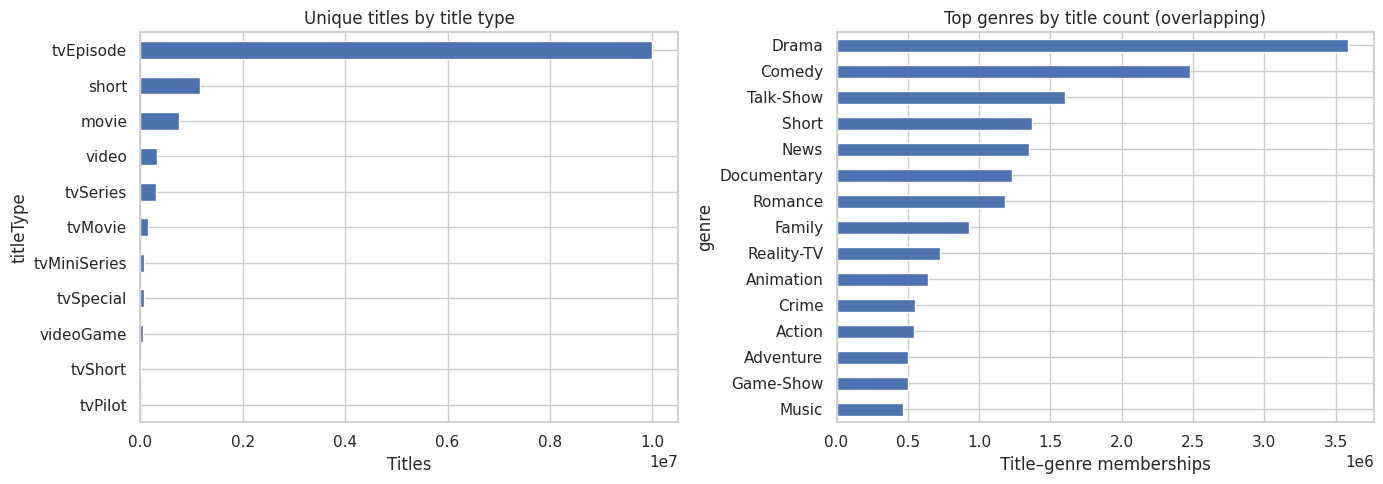

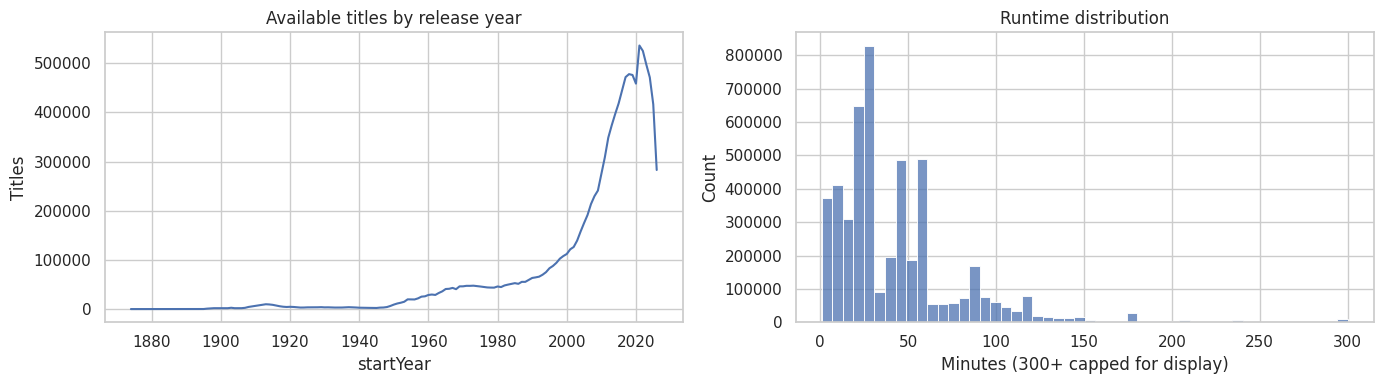

In [4]:
MIN_VOTES=1000
type_stats=df.groupby('titleType',dropna=False).agg(titles=('tconst','size'),rated=('averageRating','count'),median_rating=('averageRating','median'))
import pyarrow as pa
import pyarrow.compute as pc
genre_lists=pd.Series(pd.arrays.ArrowExtensionArray(pc.split_pattern(df.genres.array.__arrow_array__(),pattern=',')), index=df.index)
genres=df[['tconst','averageRating','numVotes']].assign(genre=genre_lists).explode('genre').dropna(subset=['genre'])
del genre_lists
genre_stats=genres.groupby('genre').agg(titles=('tconst','size'),rated=('averageRating','count'),median_rating=('averageRating','median'),median_votes=('numVotes','median'))
del genres; import gc; gc.collect()
eligible=df.dropna(subset=['averageRating','numVotes']).query('numVotes >= @MIN_VOTES').copy()
genre_eligible=eligible.assign(genre=eligible.genres.str.split(',')).explode('genre').dropna(subset=['genre'])
genre_comparison=genre_eligible.groupby('genre').agg(titles=('tconst','size'),mean_rating=('averageRating','mean'),median_rating=('averageRating','median'))
display(type_stats); display(genre_stats.sort_values('titles',ascending=False)); display(genre_comparison)
for label,t in [('types',type_stats),('genres',genre_stats),('genres_min_votes',genre_comparison)]:t.to_csv(OUT/f'imdb_{label}.csv')
fig,axes=plt.subplots(1,2,figsize=(14,5))
type_stats.titles.sort_values().plot.barh(ax=axes[0],title='Unique titles by title type'); axes[0].set_xlabel('Titles')
genre_stats.titles.nlargest(15).sort_values().plot.barh(ax=axes[1],title='Top genres by title count (overlapping)'); axes[1].set_xlabel('Title–genre memberships')
savefig('imdb_title_genres.png')
historical=df.loc[df.startYear.between(1800,current_year),['startYear','decade','titleType','tconst','averageRating','runtimeMinutes']].copy()
fig,axes=plt.subplots(1,2,figsize=(14,4))
historical.groupby('startYear').size().plot(ax=axes[0],title='Available titles by release year'); axes[0].set_ylabel('Titles')
sns.histplot(df.runtimeMinutes.dropna().clip(upper=300),bins=50,ax=axes[1]); axes[1].set(title='Runtime distribution',xlabel='Minutes (300+ capped for display)')
savefig('imdb_year_runtime.png')

## 4. Ratings, votes and time periods
Display eligible high-rated titles with vote counts so a one-vote title cannot lead the ranking. Repeat rankings at several minimum-vote thresholds. Votes indicate participation, not revenue or unique viewing audiences. Pooled correlations mix different title types; a movie-only sensitivity table is included.

,primaryTitle,titleType,startYear,averageRating,numVotes
9263250,IShowSpeed: Early Stream!,video,2021.0,10.0,27014.0
9522862,Mayookha,movie,2026.0,10.0,2120.0
9210534,Sohla: Celebration Under the Grey Sky,movie,2026.0,10.0,1253.0
9963779,Battle of the Bastards,tvEpisode,2016.0,9.9,316228.0
9963831,The Winds of Winter,tvEpisode,2016.0,9.9,234161.0
5543249,The Rains of Castamere,tvEpisode,2013.0,9.9,188994.0
8381811,I Thought You'd Never Shut Up,tvEpisode,2025.0,9.9,100989.0
2173605,Plan and Execution,tvEpisode,2022.0,9.9,90486.0
9609187,Don't Do Anything Rash,tvEpisode,2026.0,9.9,53260.0
12078397,407 Proxy Authentication Required,tvEpisode,2019.0,9.9,49192.0


Min votes=100: titles=435,185, median rating=7.10
Min votes=1000: titles=108,974, median rating=7.20
Min votes=10000: titles=18,378, median rating=7.00


,averageRating,numVotes,runtimeMinutes,startYear
averageRating,1.000000,0.016974,-0.469333,0.090403
numVotes,0.016974,1.000000,0.212137,-0.028159
runtimeMinutes,-0.469333,0.212137,1.000000,-0.099215
startYear,0.090403,-0.028159,-0.099215,1.000000


,averageRating,numVotes,runtimeMinutes,startYear
averageRating,1.000000,0.204314,0.283584,-0.156501
numVotes,0.204314,1.000000,0.171776,-0.003754
runtimeMinutes,0.283584,0.171776,1.000000,0.185930
startYear,-0.156501,-0.003754,0.185930,1.000000


titles  rated  median_rating  median_runtime
decade titleType                                              
1870   short          32     32           5.30             1.0
1880   short          79     79           4.90             1.0
1890   movie          18     18           3.65            80.5
       short        6101   4178           4.10             1.0
1900   movie         183    183           3.40            60.0
...                  ...    ...            ...             ...
2020   tvSeries    73373  29942           7.00            35.0
       tvShort       553    105           7.10            12.0
       tvSpecial   19400   4388           6.80            60.0
       video       61114   3614           7.30            23.0
       videoGame   11057   3511           7.00            45.0

[115 rows x 4 columns]

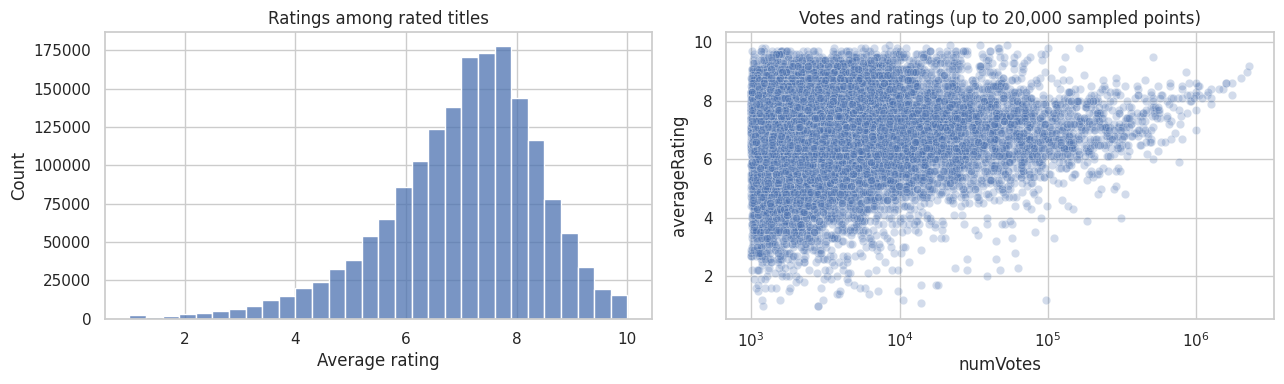

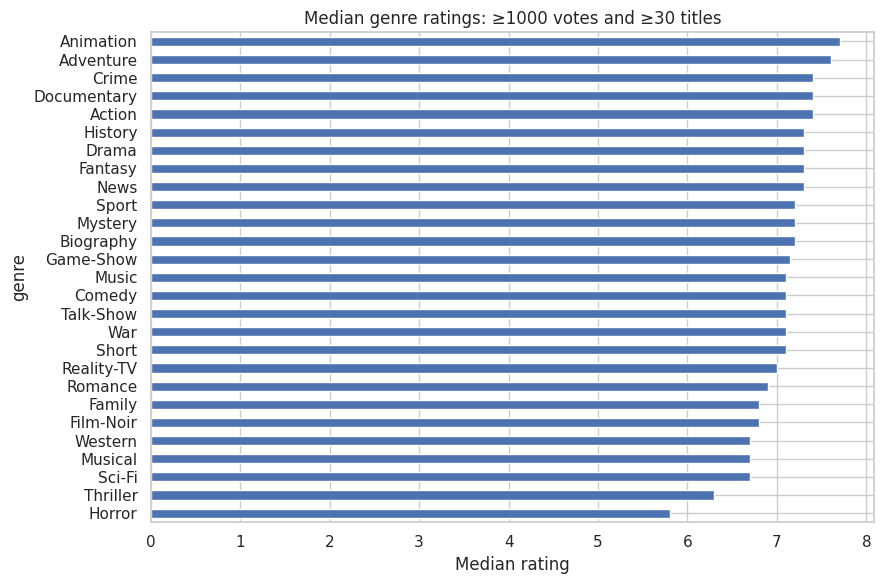

In [5]:
top=eligible.sort_values(['averageRating','numVotes'],ascending=False).head(20)
display(top[['primaryTitle','titleType','startYear','averageRating','numVotes']])
top.to_csv(OUT/'imdb_high_rated_titles.csv',index=False)
for cutoff in [100,1000,10000]:
    sub=df[df.numVotes>=cutoff]
    print(f'Min votes={cutoff}: titles={len(sub):,}, median rating={sub.averageRating.median():.2f}')
num=['averageRating','numVotes','runtimeMinutes','startYear']
display(eligible[num].corr(method='spearman'))
display(eligible[eligible.titleType=='movie'][num].corr(method='spearman'))
periods=historical.groupby(['decade','titleType']).agg(titles=('tconst','size'),rated=('averageRating','count'),median_rating=('averageRating','median'),median_runtime=('runtimeMinutes','median'))
display(periods); periods.to_csv(OUT/'imdb_periods_by_type.csv')
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(df.averageRating.dropna(),bins=30,ax=axes[0]); axes[0].set(title='Ratings among rated titles',xlabel='Average rating')
plot=eligible.sample(min(20000,len(eligible)),random_state=26)
sns.scatterplot(data=plot,x='numVotes',y='averageRating',alpha=.25,ax=axes[1]); axes[1].set(xscale='log',title='Votes and ratings (up to 20,000 sampled points)')
savefig('imdb_ratings_votes.png')
g=genre_comparison[genre_comparison.titles>=30].sort_values('median_rating')
if not g.empty:
    g.median_rating.plot.barh(figsize=(9,6),title=f'Median genre ratings: ≥{MIN_VOTES} votes and ≥30 titles'); plt.xlabel('Median rating'); savefig('imdb_genre_ratings.png')

## 5. Short report
Conclusions apply to the downloaded snapshot. Release-year changes can reflect coverage, title mix and incomplete recent years, not simply changing audience preferences.

In [6]:
qualified=genre_comparison[genre_comparison.titles>=30].sort_values('median_rating',ascending=False)
best='No genre meets the sample-size requirement.' if qualified.empty else f'{qualified.index[0]} (median {qualified.iloc[0].median_rating:.2f}; n={int(qualified.iloc[0].titles)}).'
report('imdb_report.md',f"""# IMDb — findings
- Source files: {len(basics_paths)} complete metadata part(s), {ratings_path.name}.
- Clean metadata titles: {len(df):,}; rated titles: {df.averageRating.notna().sum():,}.
- Rating coverage: {df.averageRating.notna().mean():.1%}.
- Median rating among rated titles: {df.averageRating.median():.2f}.
- Titles with at least {MIN_VOTES:,} votes: {len(eligible):,}.
- Leading genre by eligible median rating (at least 30 titles): {best}

## Interpretation and actions
Use genre comparisons to shortlist content for further audience research. Inspect title-type and decade tables before interpreting aggregate differences. Compare high-rated titles alongside vote counts and test whether rankings change with the vote threshold. Do not treat high ratings as evidence of commercial success.

## Limitations
Multiple genres per title, missing ratings, selection bias among voters, unequal vote counts, historical snapshot coverage and mixed title types limit generalization. Correlations are not causal. The latest year may be incomplete. No revenue data are analyzed.

## Evidence
See imdb_*.csv tables in this folder and ../figures/imdb_*.png. Scatterplots are sampled for rendering; tables use the full loaded data.
""")

# IMDb — findings
- Source files: 26 complete metadata part(s), title.ratings.tsv.gz.
- Clean metadata titles: 12,917,629; rated titles: 1,727,596.
- Rating coverage: 13.4%.
- Median rating among rated titles: 7.20.
- Titles with at least 1,000 votes: 108,974.
- Leading genre by eligible median rating (at least 30 titles): Animation (median 7.70; n=15563).

## Interpretation and actions
Use genre comparisons to shortlist content for further audience research. Inspect title-type and decade tables before interpreting aggregate differences. Compare high-rated titles alongside vote counts and test whether rankings change with the vote threshold. Do not treat high ratings as evidence of commercial success.

## Limitations
Multiple genres per title, missing ratings, selection bias among voters, unequal vote counts, historical snapshot coverage and mixed title types limit generalization. Correlations are not causal. The latest year may be incomplete. No revenue data are analyzed.

## Evidence